# The electron-screening anomaly in deuterated metals

Notebook 01 found one measured fact that standard theory doesn't explain. Fusion experiments that fire deuterium beams at deuterium-loaded metals see low-energy reaction rates that imply a **screening energy** $U_e$ of about 200–600 eV. Gas targets give about 25 eV, which matches atomic theory (the adiabatic limit, about 28 eV).

This notebook asks five questions:

1. **What exactly was measured?** (§1–2)
2. **Could it be an experimental artifact?** We simulate the critics' proposed mechanism (§3).
3. **Does the textbook explanation hold up?** The Debye plasma model fits the numbers but fails basic consistency checks (§4–5).
4. **If it's real, does it matter for cold fusion?** The answer is more interesting than notebook 01 suggested, and it **corrects a claim made there** (§6).
5. **What do the 2025–2026 results add?** (§7–8)

> **Source caveat:** primary journals (Nature, APS, MDPI, arXiv) couldn't be fetched from the build environment. Values come from search-indexed abstracts and summaries, and each carries a status in the final table.

In [1]:
import numpy as np
from scipy import optimize, integrate
import matplotlib.pyplot as plt
plt.rcParams.update({"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,
                     "grid.alpha":.25,"font.size":10,"axes.titlesize":11})
BLUE, ORANGE, AQUA, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e"

e2_eVA = 14.3996      # e^2/(4 pi eps0) in eV*Angstrom
B_G    = 31.3970      # D+D Gamow constant, sqrt(keV), centre-of-mass
kB     = 8.617333e-5  # eV/K
eps0, qe, kJ = 8.8541878e-12, 1.602176634e-19, 1.380649e-23

def sigma_ratio(E, U):
    # enhancement f = sigma_screened/sigma_bare, using the standard energy shift E -> E+U  (E,U in keV, c.m.)
    return np.exp(B_G/np.sqrt(E) - B_G/np.sqrt(E+U))

## 1. Reported screening energies (d+d)

Values only as reliable as the source status in §9. Raiola et al.'s tantalum value appears as both 309±12 and 340±14 eV in different sources.

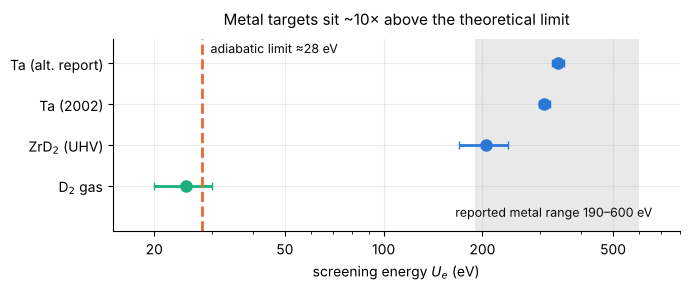

In [2]:
data = [  # label, U_e (eV), err, kind, source
 ("D$_2$ gas",           25,  5,  "gas",    "Greife et al. 1995 via LUNA overview"),
 ("ZrD$_2$ (UHV)",      205, 35,  "metal",  "Czerski group (exact value unverified)"),
 ("Ta (2002)",          309, 12,  "metal",  "Raiola et al. EPJA 13, 377"),
 ("Ta (alt. report)",   340, 14,  "metal",  "conference report of same group"),
]
U_ad = 28.0
from matplotlib.ticker import FixedLocator, NullFormatter, FuncFormatter
fig, ax = plt.subplots(figsize=(7,3.0))
ax.axvspan(190, 600, color=MUTED, alpha=.12, lw=0)
ax.text(330, -0.75, "reported metal range 190–600 eV", ha="center", fontsize=9, color=INK)
for i,(lab,U,err,kind,_) in enumerate(data):
    ax.errorbar(U, i, xerr=err, fmt="o", ms=8, color=AQUA if kind=="gas" else BLUE, capsize=3, lw=2)
ax.axvline(U_ad, color=ORANGE, ls="--", lw=2)
ax.text(U_ad*1.06, 3.25, "adiabatic limit ≈28 eV", color=INK, fontsize=9)
ax.set_yticks(range(len(data))); ax.set_yticklabels([d[0] for d in data]); ax.set_ylim(-1.1, 3.6)
ax.set_xscale("log"); ax.set_xlim(15, 800)
ax.xaxis.set_major_locator(FixedLocator([20, 50, 100, 200, 500])); ax.xaxis.set_minor_formatter(NullFormatter())
ax.xaxis.set_major_formatter(FuncFormatter(lambda v,_: f"{v:g}"))
ax.set_xlabel("screening energy $U_e$ (eV)")
ax.set_title("Metal targets sit ~10× above the theoretical limit", pad=10)
plt.tight_layout(); plt.savefig("../figures/02_ue_values.png", dpi=130); plt.show()

## 2. What $U_e$ means and how it is extracted

At c.m. energy $E$, screening acts like an energy boost: $\sigma_s(E)\approx\sigma(E+U_e)$, so

$$f(E)=\frac{\sigma_s}{\sigma_{bare}} = \exp\!\left(\frac{B_G}{\sqrt E}-\frac{B_G}{\sqrt{E+U_e}}\right)\approx \exp\!\left(\frac{B_G U_e}{2E^{3/2}}\right).$$

Experiments measure yields at E ≈ 2.5–30 keV (c.m.), take the bare cross-section from gas data, and fit $U_e$ to how $f$ rises at low energy.

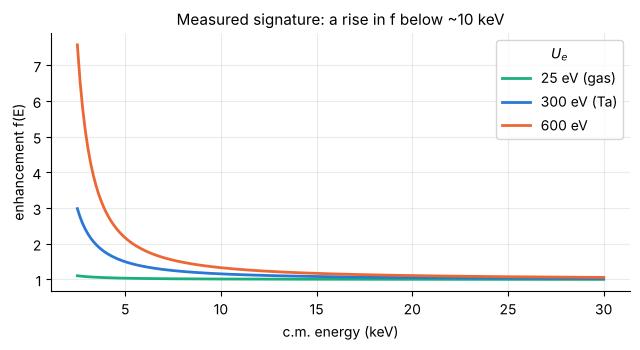

U_e=  25 eV:  f(2.5 keV)=1.10  f(5)=1.04  f(10)=1.012
U_e= 300 eV:  f(2.5 keV)=2.99  f(5)=1.50  f(10)=1.157
U_e= 600 eV:  f(2.5 keV)=7.58  f(5)=2.17  f(10)=1.330

classical turning point at 2.5 keV: 0.0058 A  (the region the beam data actually probe)


In [3]:
E = np.linspace(2.5, 30, 200)
fig, ax = plt.subplots(figsize=(6.5,3.6))
for U,col,lab in [(0.025,AQUA,"25 eV (gas)"),(0.3,BLUE,"300 eV (Ta)"),(0.6,ORANGE,"600 eV")]:
    ax.plot(E, sigma_ratio(E,U), color=col, lw=2, label=lab)
ax.set_xlabel("c.m. energy (keV)"); ax.set_ylabel("enhancement f(E)"); ax.legend(title="$U_e$")
ax.set_title("Measured signature: a rise in f below ~10 keV")
plt.tight_layout(); plt.savefig("../figures/02_enhancement.png", dpi=130); plt.show()
for U in [0.025,0.3,0.6]:
    print(f"U_e={U*1e3:4.0f} eV:  f(2.5 keV)={sigma_ratio(2.5,U):.2f}  f(5)={sigma_ratio(5,U):.2f}  f(10)={sigma_ratio(10,U):.3f}")
print("\nclassical turning point at 2.5 keV:", f"{e2_eVA/2500:.4f} A  (the region the beam data actually probe)")

**Key point:** at a 300 eV screening energy the signal is a factor of about 3 at the lowest energy (2.5 keV), 1.5 at 5 keV and 16% at 10 keV. The whole measurement rests on a few low-energy points, so anything that varies with energy and inflates those points feeds straight into $U_e$. The beam data also only probe separations below about 0.006 Å.

## 3. Can an artifact produce a fake $U_e$?

Huke, Czerski & Heide (2008) argued that surface contamination and **deuterium density changing with depth** imitate screening. Lower-energy beams stop closer to the surface. If the surface layer holds more deuterium than the bulk, low-energy yields come out too high, which looks exactly like screening.

The model below has **no screening at all** ($U_e=0$). The near-surface deuterium excess is $g(E)=1+A\,e^{-E/E_1}$, and we fit $U_e$ the way the experiments do.

In [4]:
Efit = np.linspace(2.5, 30, 25)
def fake_U(A, E1):
    g = 1 + A*np.exp(-Efit/E1)
    res = optimize.least_squares(lambda p: np.log(sigma_ratio(Efit, p[0])*p[1]) - np.log(g), [0.1, 1.0], bounds=([0,0.5],[5,2]))
    return res.x[0]*1e3
print(" surface excess A   depth scale E1(keV)  ->  fitted 'U_e' (eV), true U_e = 0")
for A in [0.1, 0.25, 0.5]:
    for E1 in [3, 6]:
        print(f"      {A:4.2f}              {E1:3d}                {fake_U(A,E1):6.0f}")
print("\nsurface excess needed to fake a given U_e:")
for target in [100, 300]:
    for E1 in [3, 6]:
        A = optimize.brentq(lambda A: fake_U(A,E1)-target, 0.01, 50)
        print(f"   fake U_e = {target} eV with E1 = {E1} keV  ->  A = {A:.1f}  (near-surface D density {1+A:.1f}x bulk)")

 surface excess A   depth scale E1(keV)  ->  fitted 'U_e' (eV), true U_e = 0
      0.10                3                    12
      0.10                6                    19
      0.25                3                    30
      0.25                6                    46
      0.50                3                    57
      0.50                6                    88

surface excess needed to fake a given U_e:
   fake U_e = 100 eV with E1 = 3 keV  ->  A = 0.9  (near-surface D density 1.9x bulk)
   fake U_e = 100 eV with E1 = 6 keV  ->  A = 0.6  (near-surface D density 1.6x bulk)
   fake U_e = 300 eV with E1 = 3 keV  ->  A = 3.5  (near-surface D density 4.5x bulk)
   fake U_e = 300 eV with E1 = 6 keV  ->  A = 2.2  (near-surface D density 3.2x bulk)


**Result (and a correction to my own expectation):** a modest 10–50% surface excess fakes only **about 10–90 eV**. That's enough to blur the gas-vs-theory comparison but **not enough to make 300 eV**. Faking 300 eV needs the near-surface deuterium density to be several times the bulk (see the output above). That's possible under intense beam implantation into a low-solubility metal, but it's a strong requirement, not a minor systematic. So the simplest artifact explains part of the anomaly and probably not all of it, unless depth profiles really are that steep. Only measuring them can settle it. Huke et al.'s ultra-high-vacuum Zr data came out *lower* than earlier values, and Lipoglavšek's group traces part of the effect to lattice stress and trapping sites at the surface. Czerski's later Zr work found carbon and oxygen contamination had little influence.

## 4. The Debye model: right numbers, wrong physics

Raiola et al. explained the anomaly by treating the metal's conduction electrons as a classical plasma:

$$U_D = \frac{e^2}{4\pi\varepsilon_0\lambda_D},\qquad \lambda_D=\sqrt{\frac{\varepsilon_0 kT}{e^2 n_{\rm eff}}}$$

With roughly one free electron per atom it reproduces about 300 eV. But the model is only valid if (a) the electrons are non-degenerate ($T \gg T_F$) and (b) many electrons sit inside a Debye sphere. The cell below checks both.

In [5]:
metals = {  # atomic density (m^-3), Fermi energy (eV, free-electron, standard tables), n_eff (valence e-/atom assumed)
  "Ta": (5.54e28, None, 1.0),
  "Pd": (6.80e28, None, 1.0),
  "Zr": (4.29e28, None, 1.0),
}
T = 293.0
print(" metal   lambda_D (A)   U_Debye (eV)   electrons in Debye sphere   T_F/T     Thomas-Fermi lambda (A)   U_TF (eV)")
for m,(rho,_,neff) in metals.items():
    n = neff*rho
    lamD = np.sqrt(eps0*kJ*T/(qe**2*n))
    UD = e2_eVA/(lamD*1e10)
    ND = 4/3*np.pi*n*lamD**3
    EF = (1.0546e-34**2/(2*9.109e-31))*(3*np.pi**2*n)**(2/3)/qe   # free-electron Fermi energy
    TF_T = EF/(kB*T)
    lamTF = np.sqrt(2*eps0*EF*qe/(3*qe**2*n))                       # Thomas-Fermi length
    UTF = e2_eVA/(lamTF*1e10)
    print(f"  {m:3s}     {lamD*1e10:.4f}        {UD:6.0f}           {ND:.1e}               {TF_T:6.0f}       {lamTF*1e10:.3f}               {UTF:5.1f}")

 metal   lambda_D (A)   U_Debye (eV)   electrons in Debye sphere   T_F/T     Thomas-Fermi lambda (A)   U_TF (eV)
  Ta      0.0502           287           2.9e-05                  210       0.594                24.3
  Pd      0.0453           318           2.6e-05                  241       0.574                25.1
  Zr      0.0570           252           3.3e-05                  177       0.620                23.2


**Result:**

* With one electron per atom, Debye gives **about 270–320 eV**. That's the right size, which explains why the model caught on.
* But the Debye sphere holds **about 3×10⁻⁵ electrons**. A screening cloud can't be built from a few hundred-thousandths of an electron, so the formula is being used far outside its validity.
* Metal electrons are degenerate: $T_F/T \approx 200$. The correct static screening is **Thomas–Fermi**, about 0.6 Å, which gives **about 23–25 eV**, matching the adiabatic limit and the gas data almost exactly.

So the standard physics predicts about 25 eV. The measurements say about 300. The one model that fits is inconsistent with itself. Later theory using self-consistent dielectric functions reportedly still falls short of the data by a factor of about 3 (status: secondary report).

## 5. A sharp test: temperature dependence

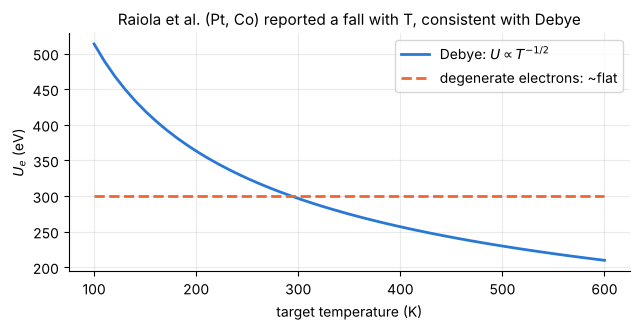

Debye predicts U(600 K)/U(300 K) = 0.71


In [6]:
Ts = np.linspace(100, 600, 50)
fig, ax = plt.subplots(figsize=(6.5,3.4))
U293 = 300
ax.plot(Ts, U293*np.sqrt(293/Ts), color=BLUE, lw=2, label="Debye: $U\\propto T^{-1/2}$")
ax.plot(Ts, np.full_like(Ts, U293), color=ORANGE, lw=2, ls="--", label="degenerate electrons: ~flat")
ax.set_xlabel("target temperature (K)"); ax.set_ylabel("$U_e$ (eV)"); ax.legend()
ax.set_title("Raiola et al. (Pt, Co) reported a fall with T, consistent with Debye")
plt.tight_layout(); plt.savefig("../figures/02_temperature.png", dpi=130); plt.show()
print(f"Debye predicts U(600 K)/U(300 K) = {np.sqrt(300/600):.2f}")

Raiola et al. reported $U_e$ falling with temperature in Pt and Co, as Debye predicts. But heating also drives deuterium out of the near-surface layer, which shrinks the §3 artifact too. **Both explanations predict a decrease.** A clean test would hold the near-surface deuterium density fixed (measured in situ, e.g. by elastic recoil detection, ERDA) while varying temperature. As far as I could find, that hasn't been done.

## 6. Bridge to cold fusion, and a correction to notebook 01

Notebook 01 said screening "only acts inside 0.05 Å, so it's irrelevant at lattice spacing." That was **too strong**. The beam data only constrain the potential below about 0.006 Å (§2) and say nothing about its shape between 0.05 Å and 1 Å. The honest question is: *if a 300 eV screening applied at rest, at molecular scale, would it be enough?*

A heavier screening particle shrinks everything in proportion. In a D₂-like molecule, screening energy scales with the electron mass ($U\propto m^*$) and bond length with its inverse. We have two anchor points:
* $m^*=1$: Koonin–Nauenberg D₂, $3\times10^{-64}$ s⁻¹
* $m^*=206.8$ (muon): dd$\mu$ fusion, about $4\times10^{8}$ s⁻¹ (literature value, order of magnitude)

The WKB tunneling exponent scales as $\sqrt{\text{bond length}} \propto m^{*-1/2}$, so interpolate $\log_{10}\Gamma = A - B/\sqrt{m^*}$.

fit: log10(rate) = 14.0 - 77.5/sqrt(m*)
check vs Koonin-Nauenberg ('5-10x needed for claimed rates'): m*=5 -> 10^-20.7,  m*=10 -> 10^-10.5 /s

rate needed for 1 W/cm^3: 10^-10.3/s  ->  m* = 10.2
equivalent screening energy if U scales with m*: 25 eV x 10.2 = 256 eV


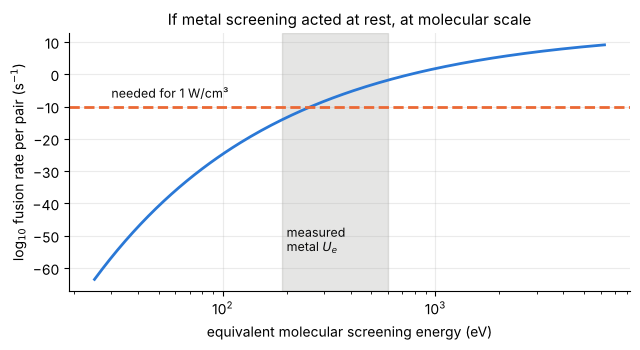

In [7]:
m1, r1 = 1.0, np.log10(3e-64)
m2, r2 = 206.77, np.log10(4e8)
B = (r2-r1)/(1-1/np.sqrt(m2)); A = r1 + B
logG = lambda m: A - B/np.sqrt(m)
print(f"fit: log10(rate) = {A:.1f} - {B:.1f}/sqrt(m*)")
print(f"check vs Koonin-Nauenberg ('5-10x needed for claimed rates'): m*=5 -> 10^{logG(5):.1f},  m*=10 -> 10^{logG(10):.1f} /s")
need = np.log10(5.6e-11)   # per-deuteron rate for 1 W/cm^3 (notebook 01)
m_need = (B/(A-need))**2
U_gas = 25.0
print(f"\nrate needed for 1 W/cm^3: 10^{need:.1f}/s  ->  m* = {m_need:.1f}")
print(f"equivalent screening energy if U scales with m*: {U_gas:.0f} eV x {m_need:.1f} = {U_gas*m_need:.0f} eV")

ms = np.logspace(0, np.log10(250), 200)
fig, ax = plt.subplots(figsize=(6.5,3.6))
ax.plot(ms*U_gas, logG(ms), color=BLUE, lw=2)
ax.axhline(need, color=ORANGE, ls="--", lw=2); ax.text(30, need+3, "needed for 1 W/cm³", color=INK, fontsize=9)
ax.axvspan(190, 600, color=MUTED, alpha=.15); ax.text(200, -55, "measured\nmetal $U_e$", fontsize=9, color=INK)
ax.set_xscale("log"); ax.set_xlabel("equivalent molecular screening energy (eV)"); ax.set_ylabel("log$_{10}$ fusion rate per pair (s$^{-1}$)")
ax.set_title("If metal screening acted at rest, at molecular scale")
plt.tight_layout(); plt.savefig("../figures/02_bridge.png", dpi=130); plt.show()

**Result:** the interpolation reproduces Koonin–Nauenberg's own statement (×5–10 brings rates to the claimed range). It says a watt-scale device needs an effective $m^*\approx 10$, or **molecular-scale screening of about 250 eV. That is the size of the measured anomaly.**

So the "50 orders of magnitude" from notebook 01 isn't independent of the screening anomaly. **Most of that gap closes if the anomalous screening worked for deuterons at rest.** That is the strongest version of your "something is missing" intuition, and it rests on measured data.

What it still requires (this is where it fails today):
1. **A binding mechanism.** A heavy electron also *pulls the pair together* (bond length / m*). Screening alone doesn't. Deuterons in Pd sit 2.75 Å apart in separate lattice sites. Something has to hold pairs at about 0.07 Å.
2. **Screening that works at rest, at 0.05–0.5 Å.** The beam data only show it for fast deuterons below about 0.006 Å. Dynamic effects at keV energies may not persist for particles at rest.
3. **Survive the §3 artifact question.**
4. **Match null results.** Loaded Pd producing 10⁻¹¹ fusions per pair per second via D+D would emit neutrons easily detected at 10⁻⁷ branch suppression. Checking this against published neutron upper limits is an open item, not done here.

The interpolation is two-anchor and crude (it ignores how the molecular potential changes shape), so treat $m^*\approx10$ as within a factor of about 2.

## 7. The 2025–2026 results

| Result | Claim | Reading |
|---|---|---|
| Chen et al., *Nature* 644, 640 (2025) | Electrochemical D loading of a Pd target raised beam-driven D+D rate by **15(2)%** | A loading-controlled change in the "anomaly zone". Fits either more near-surface D (§3) or loading-dependent screening. Neutrons measured; no excess heat claimed |
| Karahadian, …, Schenkel, Munday, *Nat. Commun.* 17, 8845 (2026) | Below about 2 keV, yield **plateaus** in Pd and Ti deuterides: **>10¹⁸** above bare-nucleus expectation | See below: a constant $U_e$ can't produce a plateau |
| Czerski group, *PRC* (2025); EPL 113, 22001 (2016) | A **0⁺ threshold resonance in ⁴He** plus e⁺e⁻/electron emission channel at low energy | A nuclear-physics explanation for part of the "screening": a resonance raises S(E) near threshold |
| Czerski et al., arXiv:2409.02112; 2605.27438 | D+D at **thermal (meV) energies** in ion tracks / metal targets (thermal-spike model) | If confirmed, direct data in the regime cold fusion needs; preprints |

In [8]:
print("Maximum possible enhancement from ANY screening = removing the whole Coulomb factor: exp(B_G/sqrt(E))")
for E in [0.25, 0.5, 0.575, 1.0, 2.0]:
    fmax = np.exp(B_G/np.sqrt(E))
    line = f"   E_cm = {E:5.3f} keV: max enhancement 10^{np.log10(fmax):5.1f}"
    if fmax > 1e18:
        U = optimize.brentq(lambda U: np.log(sigma_ratio(E,U)) - np.log(1e18), 1e-6, 1e4)
        line += f"   -> 1e18 needs U_e = {U*1e3:,.0f} eV"
    else:
        line += "   -> 1e18 impossible by screening"
    print(line)
E_lim = (B_G/np.log(1e18))**2
print(f"\n1e18 is only reachable below E_cm = {E_lim:.3f} keV (lab deuteron energy {2*E_lim:.2f} keV)")
print("with U_e = 300 eV the enhancement is:", ", ".join(f"{e} keV: {sigma_ratio(e,0.3):.1e}" for e in [0.25,0.5,1,2]))

Maximum possible enhancement from ANY screening = removing the whole Coulomb factor: exp(B_G/sqrt(E))
   E_cm = 0.250 keV: max enhancement 10^ 27.3   -> 1e18 needs U_e = 1,913 eV
   E_cm = 0.500 keV: max enhancement 10^ 19.3   -> 1e18 needs U_e = 112,351 eV
   E_cm = 0.575 keV: max enhancement 10^ 18.0   -> 1e18 impossible by screening
   E_cm = 1.000 keV: max enhancement 10^ 13.6   -> 1e18 impossible by screening
   E_cm = 2.000 keV: max enhancement 10^  9.6   -> 1e18 impossible by screening

1e18 is only reachable below E_cm = 0.574 keV (lab deuteron energy 1.15 keV)
with U_e = 300 eV the enhancement is: 0.25 keV: 7.7e+08, 0.5 keV: 1.1e+04, 1 keV: 4.7e+01, 2 keV: 4.5e+00


**Result:** an enhancement above 10¹⁸ is only possible at all where the bare Coulomb suppression is that large, below about 0.58 keV c.m. (1.15 keV lab). There, reading it as an energy shift needs **about 2 keV at 0.25 keV c.m. and over 100 keV at 0.5 keV**. That's 7× to several hundred times the field's ~300 eV anomaly, and the requirement balloons toward the 0.58 keV edge. A yield that *plateaus* means the reaction rate has become almost independent of the barrier. That isn't the shape a fixed screening shift produces. A plateau isn't the shape an energy shift produces. More likely readings are a **different mechanism** (an energetic population inside the solid such as thermal spikes or recoil cascades, the threshold resonance, or beam components) or an instrumental floor. The authors invoke material degrees of freedom renormalizing the tunneling. A critique preprint ("Beyond Scalar Screening", 2026, not peer reviewed) argues single-number screening can't be identified from the plateau. **This is the newest and most consequential claim. It needs independent replication and a careful look at backgrounds.**

## 8. What experiment would settle it?

1. **In-situ depth profiling during beam runs** (ERDA or nuclear reaction analysis) so $U_e$ is fitted with the true near-surface deuterium density. This kills or confirms the §3 artifact.
2. **Temperature scan at fixed near-surface density** (§5). Debye predicts $T^{-1/2}$; degenerate-electron theory predicts flat.
3. **Branching ratios vs energy** (p+t : n+³He : e⁺e⁻). Screening changes rates but not branching ratios. A threshold resonance changes them.
4. **Replicate the sub-keV plateau** in a second lab with H-loaded controls. Hydrogen + deuteron beams should show no D+D signal.
5. **Static test of §6:** look for D+D neutrons from heavily loaded Pd at rest, deep underground, at the rate a 250 eV molecular screening implies.

## 9. Source status

| Claim | Status | Source (as indexed) |
|---|---|---|
| D₂ gas $U_e$=25±5 eV; metals ~300 eV | Confirmed (secondary) | LUNA overview, arXiv:0906.1097 |
| Adiabatic limit ~28 eV | Confirmed (secondary) | arXiv:nucl-th/0401043 |
| Ta 309±12 eV | Confirmed / **conflict** (340±14 elsewhere) | Raiola et al. EPJA 13, 377 (2002) |
| Large in metals, small in insulators/semiconductors/lanthanides; ~58 samples | Confirmed | Raiola et al. EPJA 19, 283 (2004) |
| Debye model, n_eff matches Hall coefficient; U falls with T (Pt, Co) | Confirmed (abstract) | Raiola et al. EPJA 27 (2006) |
| Debye excluded; density dynamics mimic screening | Confirmed (abstract) | Huke, Czerski, Heide, arXiv:0805.4538 |
| Lattice stress / trapping sites | Confirmed (abstract) | Lipoglavšek group, conference proceedings |
| Dielectric theory under-predicts by ~3× | Secondary report only | Zr-target review, PMC11943714 |
| ZrD₂ 205±35 eV | **Unverified** exact value | Czerski group |
| Threshold resonance; e⁺e⁻ channel | Confirmed (abstracts) | EPL 113, 22001 (2016); PRC 2025, arXiv:2408.07567 |
| Thermal D+D in ion tracks | Preprint | arXiv:2409.02112; 2605.27438 |
| Chen et al. 15(2)% enhancement | Confirmed | *Nature* 644, 640 (2025), doi:10.1038/s41586-025-09042-7 |
| Sub-keV plateau, >10¹⁸ | Confirmed (abstract) | *Nat. Commun.* 17, 8845 (2026), arXiv:2512.06212 |
| Li+D in Pd 1500±310 eV vs Au 60±150 eV | Confirmed (abstract), different reaction | Kasagi group, JPSJ (2004) |
| ddμ fusion rate ~4×10⁸ s⁻¹ | Standard literature value, **not re-checked** | muon-catalysis reviews |
| Neutron upper limits from loaded Pd at rest | **Not checked** | open item |